# Deconvolute bulk RNA-seq

Deconvolution estimates how much of each cell type a bulk RNA-seq sample contains. The
cell types come as "signatures": the mean expression profile of each type in a
single-cell atlas. viewmastR offers two solvers on the same Poisson model, gradient
descent (`method="gd"`) and expectation maximisation (`method="em"`). This tutorial
follows the R article [How to deconvolute bulk RNAseq](https://furlan-lab.github.io/viewmastR/articles/Deconvolute.html).

| Role | Dataset |
|---|---|
| Signatures | healthy bone marrow atlas (Granja et al. 2019, "Greenleaf reference") |
| Bulk samples | sorted haematopoietic populations and AML cells (Corces et al. 2016, GEO GSE74246) |

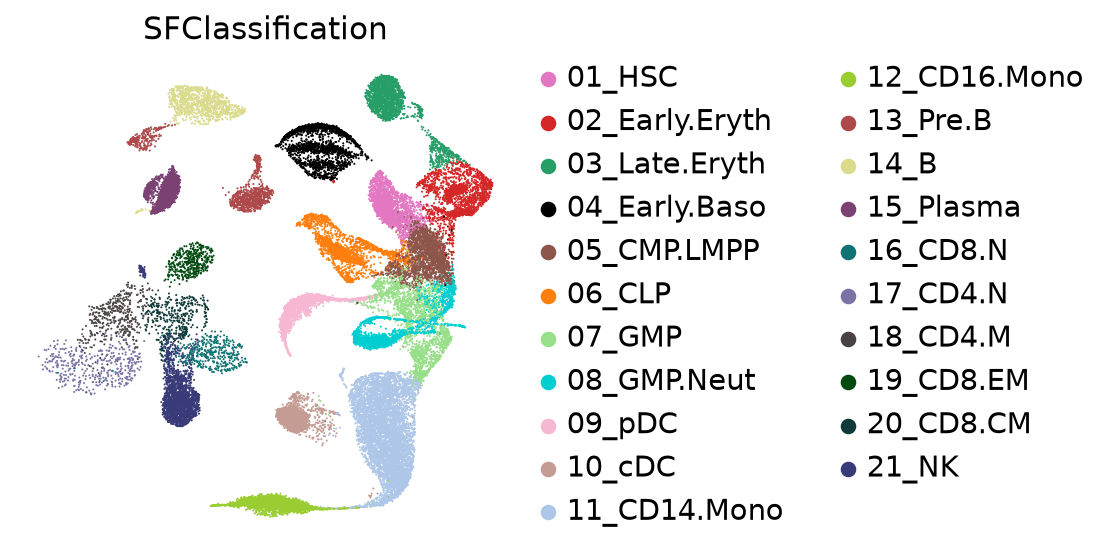

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import viewmastr as vm
import tutorial_data as td

sc.set_figure_params(dpi=80, frameon=False)
sc_data = td.greenleaf_reference()
col = "SFClassification"
vm.palette.set_colors(sc_data, col)
sc.pl.umap(sc_data, color=col)

## Signatures

Pseudobulk each cell type: the mean of library-size-normalised expression (counts per
10,000, as the R article's `expm1` of Seurat's log-normalised data).

In [2]:
x = sc_data.copy()
sc.pp.normalize_total(x, target_sum=1e4)
types = x.obs[col].astype(str)
signatures = pd.DataFrame({t: np.asarray(x[types == t].X.mean(0)).ravel() for t in sorted(types.unique())},
                          index=x.var_names)

## Bulk counts, gene lengths and weights

Use the genes found in all three tables. Gene length converts molecules to reads; a weight
of 0 excludes a gene from the fit.

In [3]:
bulk = td.corces_bulk()
info = td.gene_weights().drop_duplicates("symbol").set_index("symbol")
common = [g for g in signatures.index if g in bulk.index and g in info.index]
signatures, bulk, info = signatures.loc[common], bulk.loc[common], info.loc[common]
print(signatures.shape, bulk.shape, f"{(info.weight > 0).sum()} genes with weight > 0")

(18879, 21) (18879, 81) 16815 genes with weight > 0


## Fit both solvers

In [4]:
import time
t0 = time.time()
gd = vm.deconvolve_bulk(signatures, bulk, info["length"].to_numpy(), info["weight"].to_numpy(),
                        max_iter=3000, seed=1, verbose=False)
t1 = time.time()
em = vm.deconvolve_bulk(signatures, bulk, info["length"].to_numpy(), info["weight"].to_numpy(),
                        max_iter=3000, method="em", verbose=False)
print(f"gradient descent: {t1 - t0:.0f} s; EM: {time.time() - t1:.0f} s")

gradient descent: 296 s; EM: 103 s


## Proportions by sorted population

Leukaemic and recombinant samples are left out for clarity. The bar above each heatmap
column is the intercept: the share of signal no cell type explains.

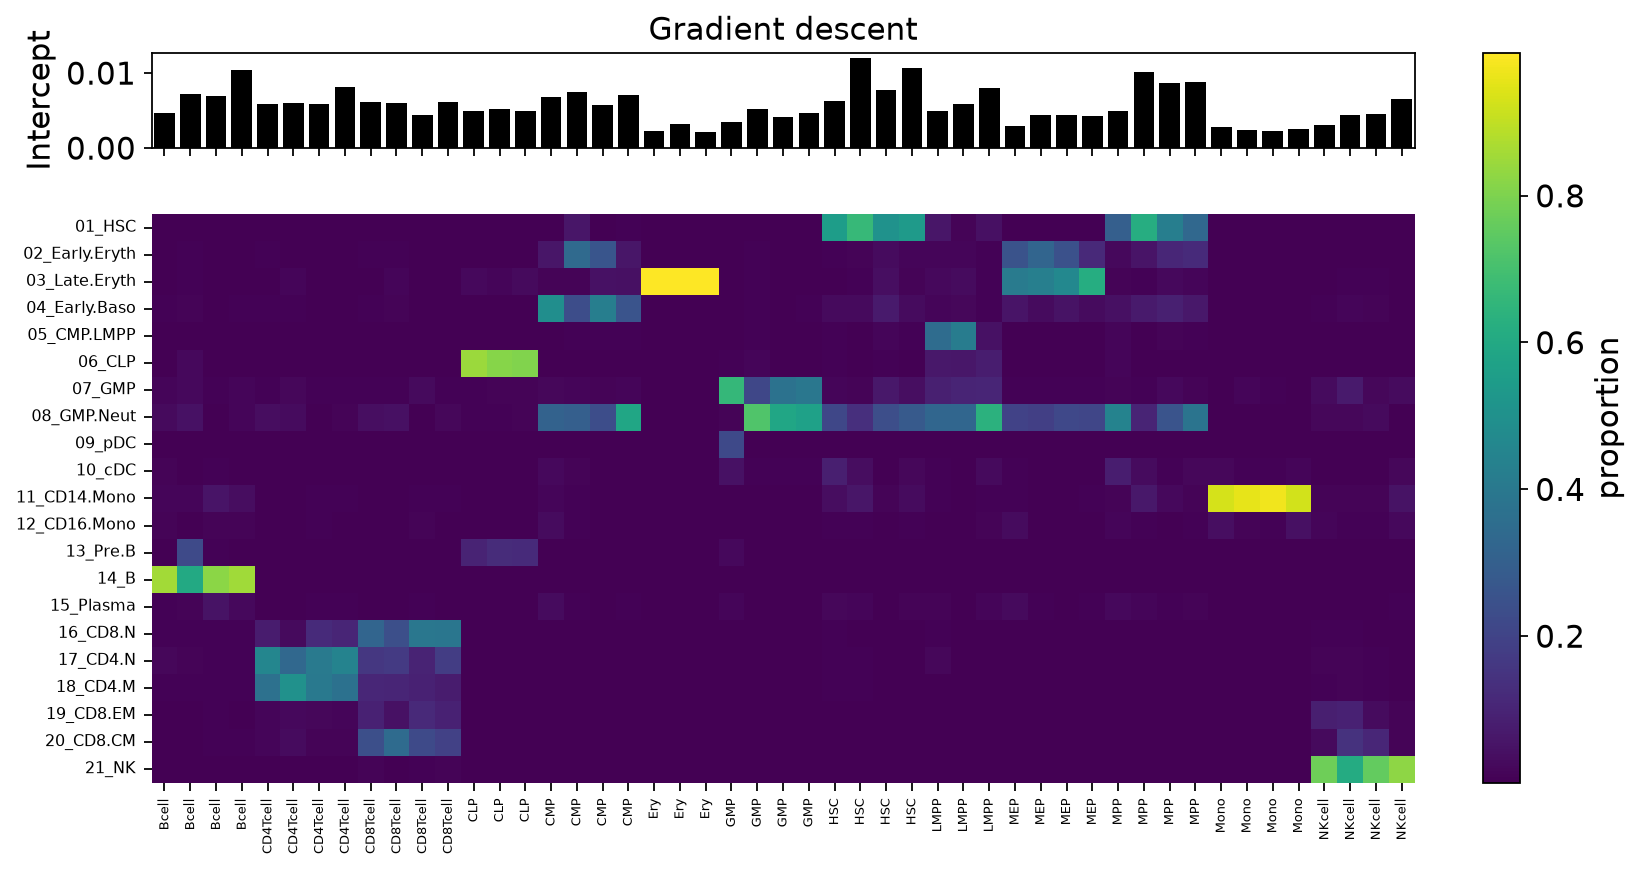

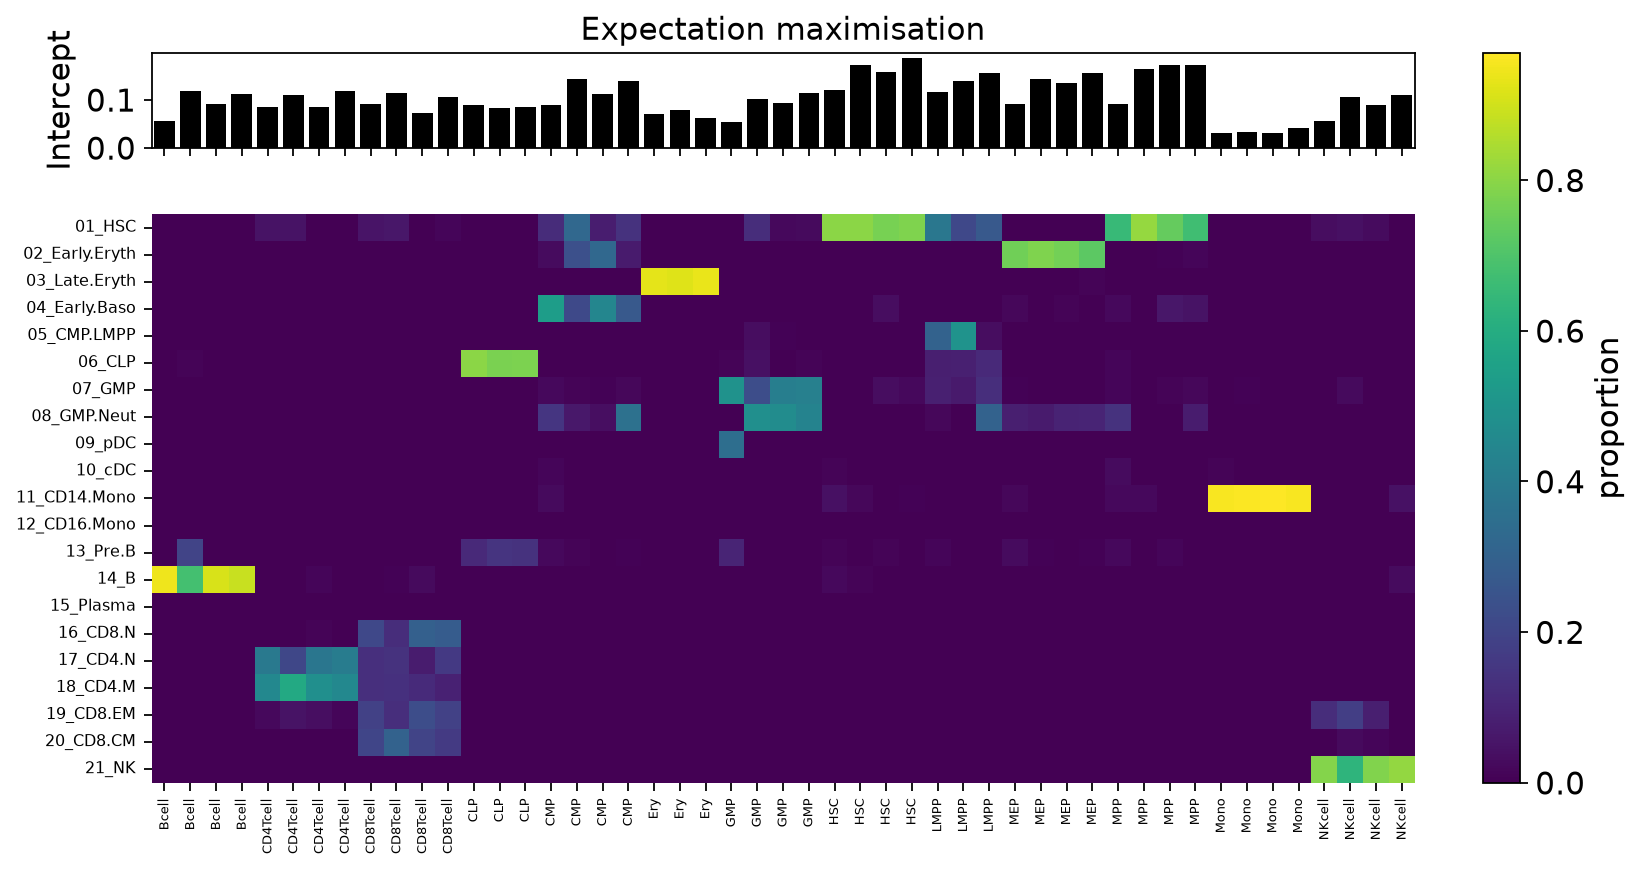

In [5]:
def heatmap(res, title):
    p = res.proportions_with_intercept
    p = p.loc[:, ~p.columns.str.contains("LSC|rHSC|Blast")]
    order = sorted(p.columns, key=lambda c: c.split("-", 1)[1])
    fig, (a0, a1) = plt.subplots(2, 1, figsize=(11, 6), height_ratios=[1, 6], sharex=True)
    a0.bar(np.arange(len(order)) + 0.5, p.loc["Intercept", order], color="black", width=0.8)
    a0.set_ylabel("Intercept")
    sns.heatmap(p.drop("Intercept").loc[:, order], cmap="viridis", ax=a1, yticklabels=True,
                cbar=False)
    for a in (a0, a1):
        a.grid(False)
    a1.tick_params(axis="y", labelsize=7)
    a1.set_xticks(np.arange(len(order)) + 0.5, [c.split("-", 1)[1] for c in order], rotation=90, fontsize=6)
    fig.colorbar(a1.collections[0], ax=(a0, a1), fraction=0.03, label="proportion")
    a0.set_title(title)
    plt.show()

heatmap(gd, "Gradient descent")
heatmap(em, "Expectation maximisation")

## Built-in diagnostics

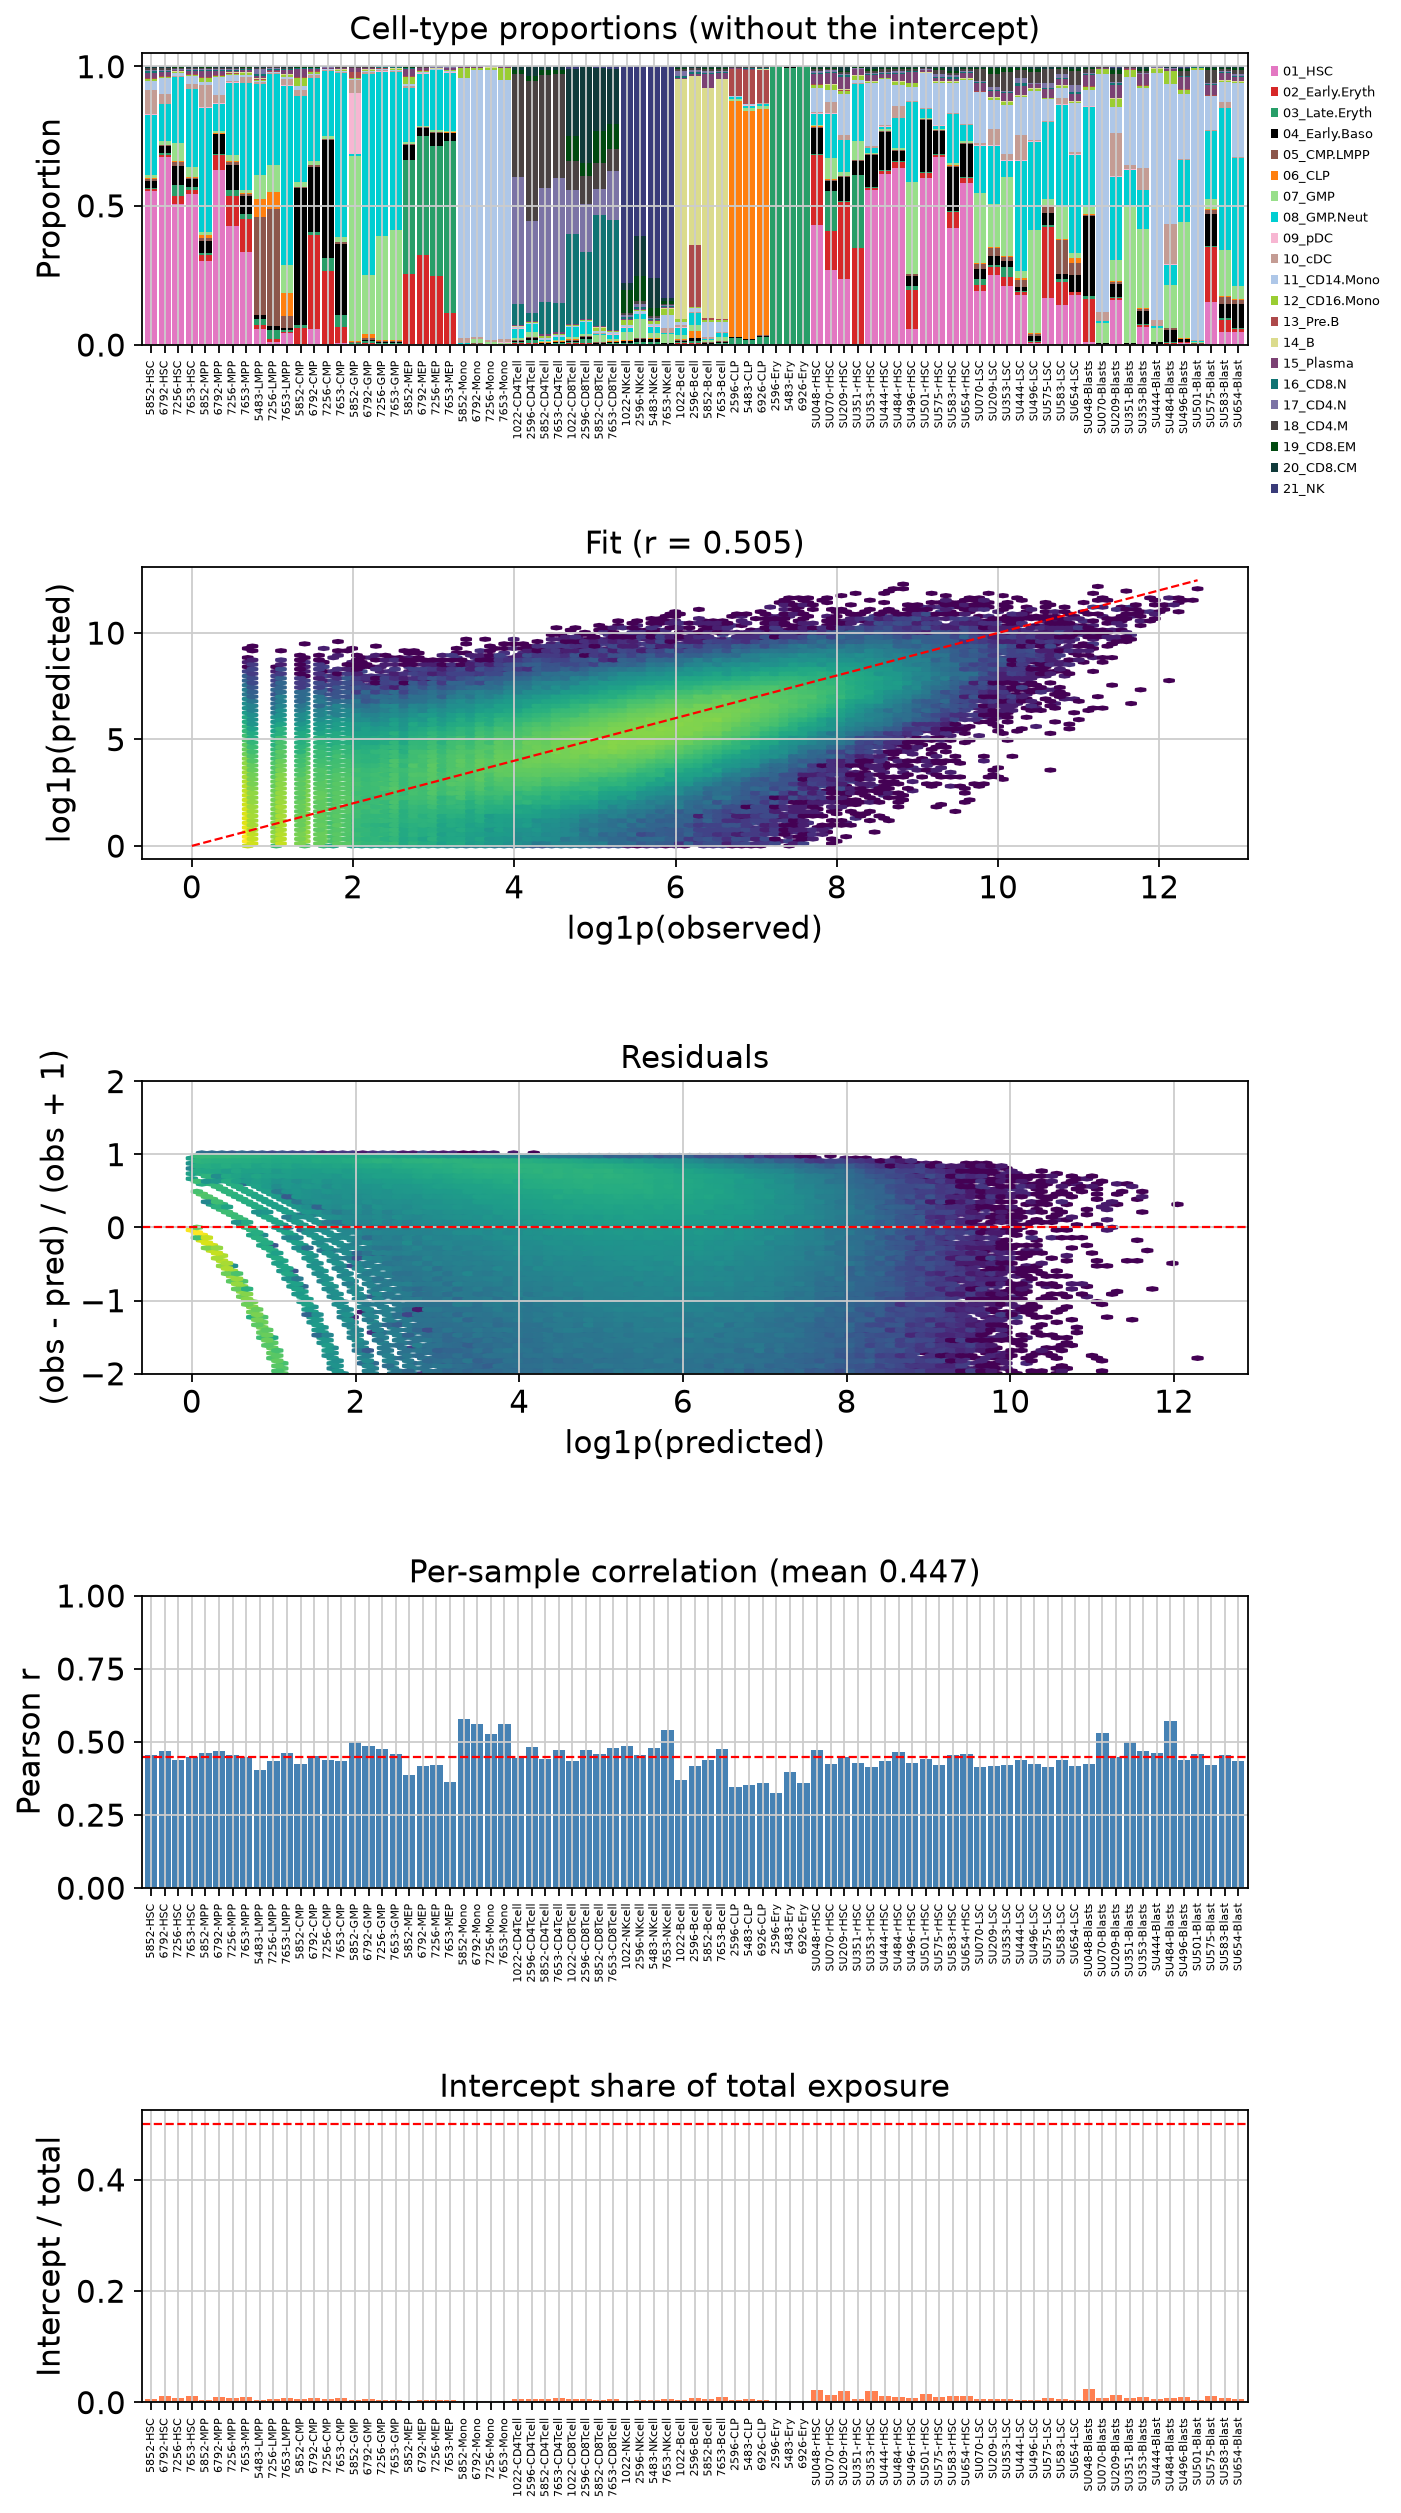

In [6]:
vm.plot_deconvolution(gd, bulk)
plt.show()

## The two solvers agree

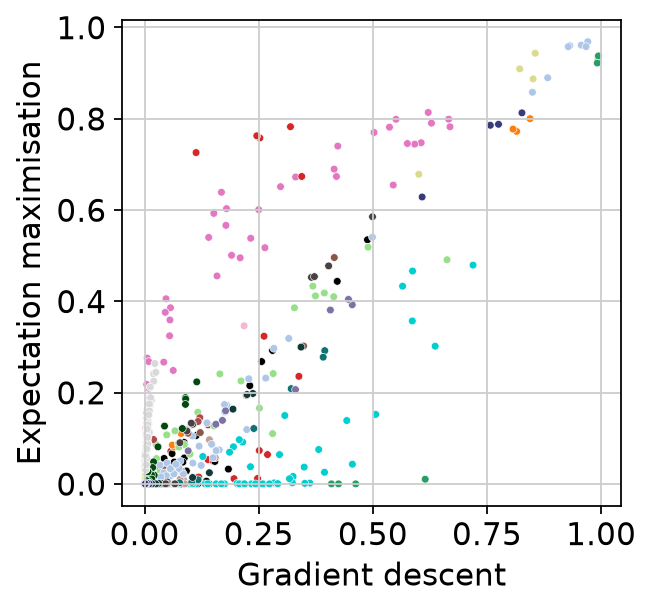

correlation: 0.852


In [7]:
df = pd.DataFrame({"gd": gd.proportions_with_intercept.to_numpy().ravel(),
                   "em": em.proportions_with_intercept.to_numpy().ravel(),
                   "celltype": np.repeat(gd.proportions_with_intercept.index, bulk.shape[1])})
sns.scatterplot(df, x="gd", y="em", hue="celltype", palette=vm.palette.colors(df.celltype), s=12,
                legend=False)
plt.xlabel("Gradient descent")
plt.ylabel("Expectation maximisation")
plt.show()
print(f"correlation: {np.corrcoef(df.gd, df.em)[0, 1]:.3f}")

## Fit quality

Observed against predicted counts on the weighted genes. The title gives R squared on the
log scale. Gradient descent predicts reads (with gene length); EM predicts molecules.

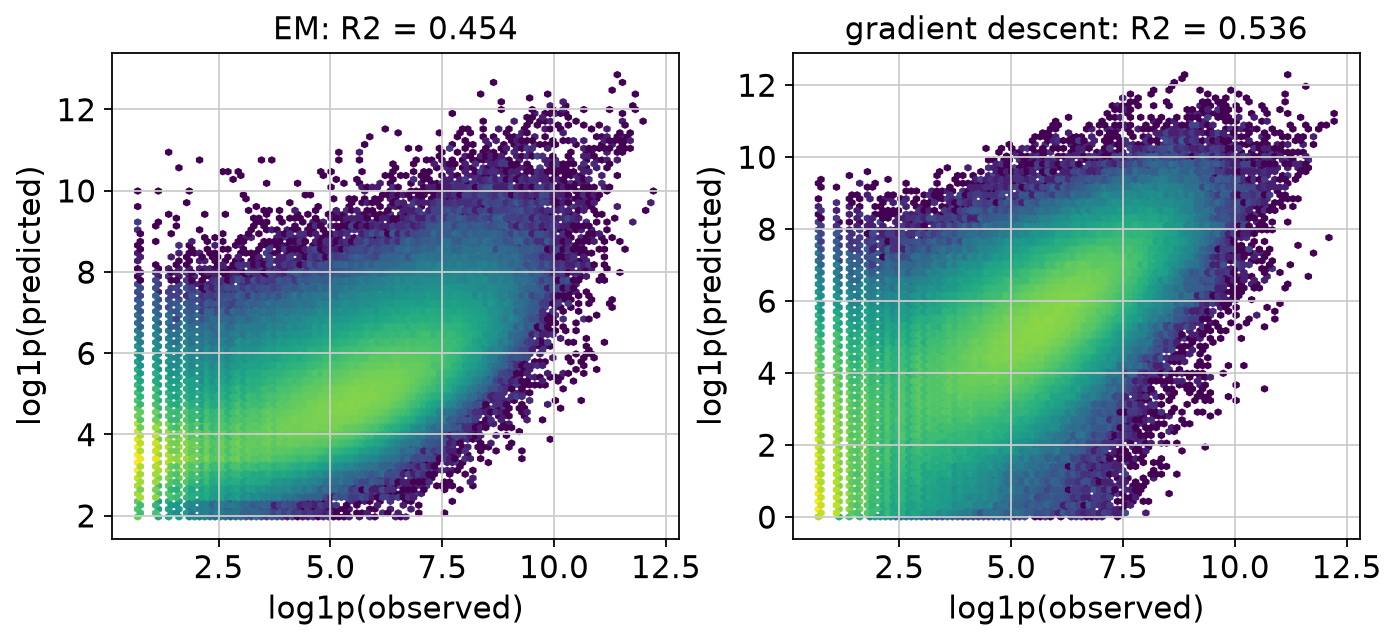

In [8]:
w = info["weight"].to_numpy() > 0
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, res) in zip(axes, (("EM", em), ("gradient descent", gd))):
    o, p = bulk.to_numpy()[w].ravel(), res.pred_counts.to_numpy()[w].ravel()
    k = (o > 0) & (p > 0)
    ax.hexbin(np.log1p(o[k]), np.log1p(p[k]), gridsize=100, bins="log", cmap="viridis")
    ax.set(title=f"{name}: R2 = {np.corrcoef(np.log1p(o[k]), np.log1p(p[k]))[0, 1] ** 2:.3f}",
           xlabel="log1p(observed)", ylabel="log1p(predicted)")
plt.show()

The R article also compares against MuSiC. MuSiC is an R-only package, so that comparison is not included here.

## The model

Both solvers fit counts `k[g, n]` of gene `g` in sample `n` as Poisson with mean
`ŷ = [S | 1/G] × [E; intercept]`, where `S` holds the signatures (columns sum to 1), `E`
the exposures and the intercept a uniform "noise" source. Gradient descent multiplies by
gene length / insert size (500) and fits log exposures with Adam (learning rate 0.01): an
intercept-only fit first, then all parameters. EM alternates two steps until the
log-likelihood stops changing: split each gene's counts between sources in proportion to
`S[g, j] × E[j, n]`, then set each exposure to its share of the weighted counts.
`l1_lambda` adds sparsity in both.

## Versions

In [9]:
from importlib.metadata import version
for pkg in ("viewmastr", "scanpy", "anndata", "numpy", "scipy"):
    print(f"{pkg:10s} {version(pkg)}")

viewmastr  0.1.0
scanpy     1.12.5
anndata    0.13.4
numpy      2.5.4
scipy      1.18.1
